Signal shape: (10240, 32)
Sampling frequency: 2048
Channel names: ['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9', 'F10', 'F11', 'F12', 'F13', 'F14', 'F15', 'F16', 'U1', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'U2', 'U3', 'W7', 'W8', 'W9', 'W10', 'W11', 'W12', 'U4']


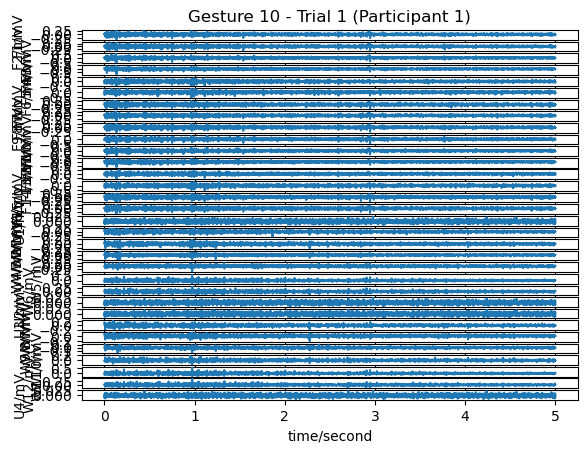

In [1]:
import wfdb
import matplotlib.pyplot as plt

# Path to one trial
path = "grabmyo_dataset/gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0/Session1/session1_participant1/session1_participant1_gesture10_trial1"

# Read signal and metadata
record = wfdb.rdrecord(path)

# Access data
signals = record.p_signal
print("Signal shape:", signals.shape)
print("Sampling frequency:", record.fs)
print("Channel names:", record.sig_name)

# Plot
wfdb.plot_wfdb(record=record, title="Gesture 10 - Trial 1 (Participant 1)")
plt.show()


In [4]:
# pip install wfdb scipy numpy pandas
import os, re, glob
import numpy as np
import pandas as pd
import wfdb
from scipy.signal import butter, filtfilt, iirnotch, welch

# === Config ===
BASE = "grabmyo_dataset/gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0/Session1/session1_participant1"
GESTURE = 10  # change if needed
FS = 2048.0   # from your header
WIN_S = 0.25  # 250 ms windows
STEP_S = 0.125  # 50% overlap
WIN = int(WIN_S * FS)
STEP = int(STEP_S * FS)

# === Channel helpers ===
def group_channels(sig_names):
    idx = {name:i for i,name in enumerate(sig_names)}
    groups = {
        "F": [idx[n] for n in sig_names if n.startswith("F")],   # Forearm? (per dataset naming)
        "W": [idx[n] for n in sig_names if n.startswith("W")],   # Wrist?
        "U": [idx[n] for n in sig_names if n.startswith("U")],   # Other/aux
        "all": list(range(len(sig_names))),
    }
    return groups

# === Filters ===
def bandpass_20_450(x, fs):
    # 4th-order zero-phase Butterworth
    ny = fs/2
    b, a = butter(4, [20/ny, 450/ny], btype='bandpass')
    return filtfilt(b, a, x, axis=0)

def notch(x, fs, freq=60.0, Q=30.0):
    b, a = iirnotch(w0=freq/(fs/2), Q=Q)
    return filtfilt(b, a, x, axis=0)

def preprocess(signals, fs):
    x = bandpass_20_450(signals, fs)
    # apply notch at 60 Hz and its first harmonic (optional)
    x = notch(x, fs, 60.0, 30.0)
    x = notch(x, fs, 120.0, 30.0)
    # per-channel z-score (robust: use median/IQR if you prefer)
    mean = x.mean(axis=0, keepdims=True)
    std = x.std(axis=0, keepdims=True) + 1e-9
    return (x - mean)/std

# === Feature extraction ===
def wl(seg):  # waveform length
    return np.sum(np.abs(np.diff(seg, axis=0)), axis=0)

def mav(seg): # mean abs value
    return np.mean(np.abs(seg), axis=0)

def rms(seg):
    return np.sqrt(np.mean(seg**2, axis=0))

def zc(seg, thr=0.01):
    s = seg
    return np.sum(((s[1:]*s[:-1] < 0) & (np.abs(s[1:] - s[:-1]) > thr)), axis=0)

def ssc(seg, thr=0.01):
    x = seg
    x1 = x[:-2]; x2 = x[1:-1]; x3 = x[2:]
    cond = (((x2 - x1)*(x2 - x3) > 0) & 
            (np.abs(x2 - x1) > thr) & (np.abs(x2 - x3) > thr))
    return np.sum(cond, axis=0)

def ar_coeffs(seg, order=4):
    # Yule-Walker via autocorr (simple, per channel)
    n = seg.shape[0]
    ks = range(order+1)
    R = np.array([[np.sum(seg[t:n-order]*seg[t-k:n-order-k], axis=0) for k in ks] for t in [0]])[0] / (n-order)
    r = R[1:]
    Rm = np.lib.stride_tricks.sliding_window_view(R, order+1)[:,0,:order]
    # solve Rm * a = r for each channel
    coeffs = []
    for ch in range(seg.shape[1]):
        try:
            a = np.linalg.solve(Rm[:, :, ch], r[:, ch])
        except np.linalg.LinAlgError:
            a = np.zeros(order)
        coeffs.append(a)
    return np.array(coeffs).T  # shape: order x channels

def spectral_feats(seg, fs):
    # Welch PSD; return mean frequency & median frequency
    f, Pxx = welch(seg, fs=fs, nperseg=min(512, len(seg)), axis=0)
    P = Pxx + 1e-12
    Psum = np.sum(P, axis=0, keepdims=True)
    mf = np.sum(f[:, None]*P, axis=0) / Psum.ravel()
    cdf = np.cumsum(P, axis=0)
    medf = []
    for ch in range(P.shape[1]):
        idx = np.searchsorted(cdf[:, ch], 0.5*Psum[0, ch])
        medf.append(f[min(idx, len(f)-1)])
    return np.array(mf), np.array(medf)

def extract_features(seg, fs, prefix=""):
    feats = {}
    feats[prefix+"RMS"] = rms(seg)
    feats[prefix+"MAV"] = mav(seg)
    feats[prefix+"WL"]  = wl(seg)
    feats[prefix+"ZC"]  = zc(seg)
    feats[prefix+"SSC"] = ssc(seg)
    ar = ar_coeffs(seg, order=4)  # shape (4, C)
    for k in range(ar.shape[0]):
        feats[f"{prefix}AR{k+1}"] = ar[k]
    mf, medf = spectral_feats(seg, fs)
    feats[prefix+"MeanFreq"] = mf
    feats[prefix+"MedianFreq"] = medf
    return feats  # dict of arrays (len = n_channels)

def windowed_features(x, fs, sig_names, gesture_id, trial_id):
    rows = []
    groups = group_channels(sig_names)
    for start in range(0, x.shape[0]-WIN+1, STEP):
        seg = x[start:start+WIN, :]
        # per-channel features
        per_ch = extract_features(seg, fs)
        # Optional group-aggregated features (mean across group)
        agg = {}
        for gname, idxs in groups.items():
            gfe = extract_features(seg[:, idxs], fs, prefix=f"{gname}_")
            # average across channels in the group
            for k,v in gfe.items():
                agg[k+"_mean"] = np.mean(v)
                agg[k+"_std"]  = np.std(v)
        # flatten to a row
        row = {
            "gesture": gesture_id,
            "trial": trial_id,
            "start_sample": start,
            "end_sample": start+WIN,
            "window_sec": start/fs,
        }
        # add per-channel as columns e.g. RMS_F1, ...
        for k, arr in per_ch.items():
            for i, name in enumerate(sig_names):
                row[f"{k}_{name}"] = arr[i]
        # add aggregates
        row.update(agg)
        rows.append(row)
    return rows

# === Loader for all Gesture 10 trials ===
def load_trials(base, gesture):
    pat = re.compile(rf"gesture{gesture}_trial(\d+)$")
    recs = []
    for hea in glob.glob(os.path.join(base, f"*gesture{gesture}_trial*.hea")):
        stem = hea[:-4]  # remove .hea
        m = pat.search(os.path.basename(stem))
        if not m: 
            continue
        trial_id = int(m.group(1))
        rec = wfdb.rdrecord(stem)
        recs.append((trial_id, rec))
    # sort by trial id
    recs.sort(key=lambda x: x[0])
    return recs

# === Run ===
all_rows = []
recs = load_trials(BASE, GESTURE)
if not recs:
    print("No .hea records found. Check BASE path.")
else:
    for trial_id, rec in recs:
        sigs = rec.p_signal if rec.p_signal is not None else rec.d_signal.astype(float)
        sig_names = rec.sig_name
        # safety: keep only first 10240 if needed
        sigs = sigs[:10240, :]  # optional, if lengths vary
        x = preprocess(sigs, FS)
        rows = windowed_features(x, FS, sig_names, GESTURE, trial_id)
        all_rows.extend(rows)

    features_df = pd.DataFrame(all_rows)
    print(features_df.shape, "feature rows x cols")
    print(features_df.columns[:12])
    print(features_df.head(3))
    # You can save:
    # features_df.to_csv("gesture10_features.csv", index=False)


ValueError: operands could not be broadcast together with shapes (508,32) (0,32) 

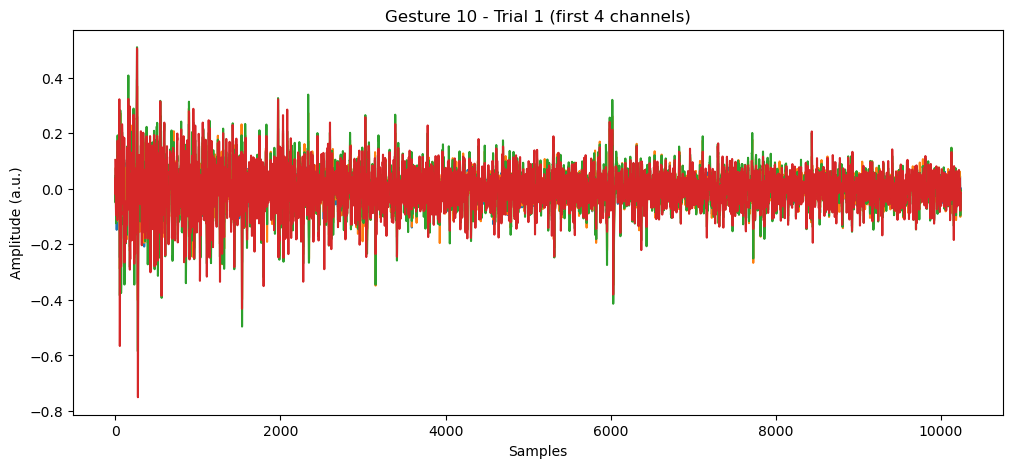

In [7]:
import wfdb
import matplotlib.pyplot as plt

path = "grabmyo_dataset/gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0/Session1/session1_participant1/session1_participant1_gesture10_trial1"
record = wfdb.rdrecord(path)

signals = record.p_signal  # already in physical units
if np.allclose(signals, 0):
    signals = record.d_signal.astype(float)  # raw integer form

plt.figure(figsize=(12, 5))
plt.plot(signals[:, 0:4])  # show a few channels
plt.title("Gesture 10 - Trial 1 (first 4 channels)")
plt.xlabel("Samples")
plt.ylabel("Amplitude (a.u.)")
plt.show()
